# Fase 3 — Pricing Bayesiano y Buffer Óptimo (Cap. 6-7)

Sobre las trayectorias del modelo SV (Cap. 5), construimos:

1. **Cap. 6 — Modelo frecuencia-severidad Bayesiano.** La liquidación es el "siniestro":
   la *frecuencia* es P(liquidación) de las trayectorias SV; la *severidad* (pérdida dado
   liquidación, LGL) se modela con una **Gamma con posterior vía MCMC**.
   Prima de riesgo:  $PR = \mathbb{E}[\,q \cdot \mathbb{E}[\text{LGL}]\,]$, propagando la
   incertidumbre posterior de la severidad.
2. **Cap. 7 — Primas por plazo × LTV** y **buffer de volatilidad óptimo Bayesiano** con
   intervalos de credibilidad.

Prima de tarifa (carga operativa, tesis de referencia):
$PT = PR / (1 - (G_{adm}+C_{adq}+U))$ con cargas por defecto 5%+10%+10% ⇒ divisor 0.75.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from tesis.data import loader
from tesis.bayesian.sv_model.stochastic_volatility import fit_sv_pymc, idata_to_mcmc_result
from tesis.bayesian.sv_model.trajectory_simulator import simulate_sv_trajectories_fast
from tesis.bayesian.pricing.bayesian_premium import (
    compute_bayesian_premium, compute_premium_table, OperationalCosts, GammaPriors)
from tesis.bayesian.buffer.bayesian_buffer import (
    compute_bayesian_buffer_distribution, find_bayesian_buffer)
from tesis.baseline.mc_bootstrap.simulator import MonteCarloPriceSimulator, BiasConfig

plt.style.use('seaborn-v0_8-whitegrid'); plt.rcParams['figure.figsize']=(12,4)
SEED=42; N_SIMS=4000; PRINCIPAL=10_000.0

## 1. Setup: reestimación del SV (idéntico al Cap. 5)

In [2]:
price=loader.load_price_series('BTC','1D'); ret=loader.compute_log_returns(price)
price_tr,price_te=loader.split_train_test(price,'2024-01-01')
ret_tr,_=loader.split_train_test(ret,'2024-01-01')
y_train=(ret_tr-ret_tr.mean()).values; start_price=float(price_tr.iloc[-1])
idata=fit_sv_pymc(y_train,n_samples=2000,n_chains=4,target_accept=0.99,tune=3000,seed=SEED)
mcmc=idata_to_mcmc_result(idata)
print(f'Precio inicial: ${start_price:,.0f} | muestras posteriores: {len(mcmc["mu"])}')

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 3_000 tune and 2_000 draw iterations (12_000 + 8_000 draws total) took 124 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Precio inicial: $42,639 | muestras posteriores: 8000


## 2. Cap. 6 — Prima Bayesiana para una configuración de referencia

Config: horizonte **365 d**, **LTV inicial 0.50**, liquidación a 0.80, fricción 1.5%, principal \$10 000.
Se simulan trayectorias, se calcula la frecuencia de liquidación, y la severidad (LGL) se ajusta con
una Gamma Bayesiana (MCMC). La prima resultante trae **intervalo de credibilidad**.

In [3]:
sv_paths=simulate_sv_trajectories_fast(mcmc,start_price,365,n_trajectories=N_SIMS,seed=1)
res=compute_bayesian_premium(sv_paths, mcmc, init_ltv=0.50, liq_ltv=0.80, friction=0.015,
                             principal_usd=PRINCIPAL, seed=SEED)
print('Método:', res['method'])
print(f"Frecuencia liquidación  q = {res['p_liq']:.3f}  ({res['n_liquidations']}/{res['n_trajectories']})")
print(f"Severidad E[LGL] post.    = {res['mean_lgl_posterior']:.3f}  IC95% {np.round(res['lgl_95ci'],3)}")
print(f"Gamma posterior: alpha={res['gamma_alpha_mean']:.2f}, beta={res['gamma_beta_mean']:.2f}")
print(f"Prima de RIESGO  = {res['risk_premium_frac']:.4f}  (${res['risk_premium_usd']:.0f})  IC95% frac {np.round(res['risk_premium_95ci_frac'],4)}")
print(f"Prima de TARIFA  = {res['tariff_premium_frac']:.4f}  (${res['tariff_premium_usd']:.0f})")

Método: bayesian_gamma_severity
Frecuencia liquidación  q = 0.517  (2069/4000)
Severidad E[LGL] post.    = 0.323  IC95% [0.302 0.346]
Gamma posterior: alpha=1.46, beta=4.53
Prima de RIESGO  = 0.1672  ($1672)  IC95% frac [0.156  0.1789]
Prima de TARIFA  = 0.2229  ($2229)


## 3. Distribución de severidad (LGL) y frecuencia

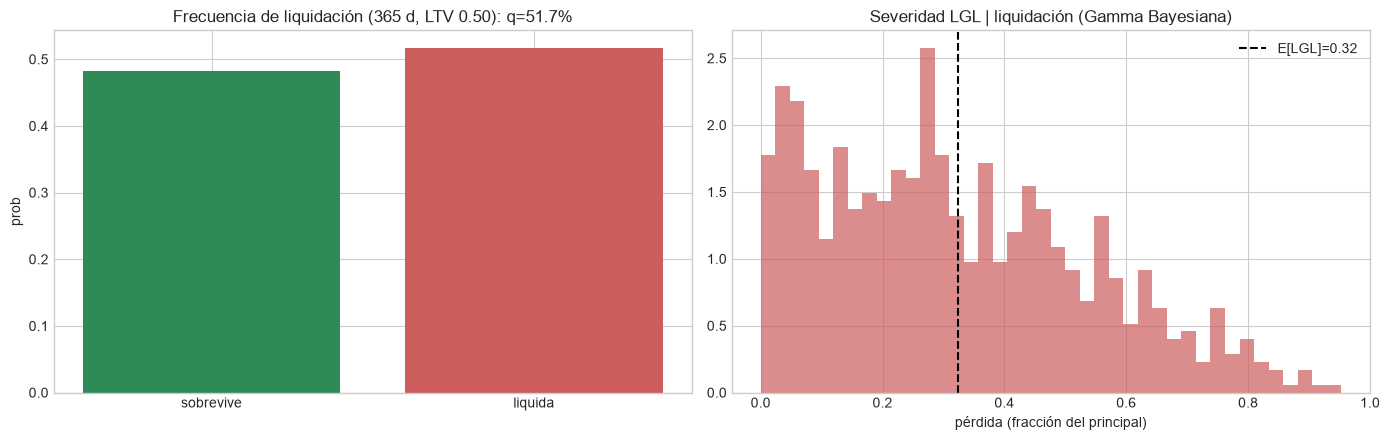

In [4]:
first=sv_paths.iloc[0].values; last=sv_paths.iloc[-1].values; mins=sv_paths.min().values
liq_ratio=0.50/0.80; liq_mask=(mins/first)<liq_ratio
recovery=last*(1-0.015); lgl=np.maximum(0.0, 1.0 - recovery/(0.50*first))
lgl_liq=lgl[liq_mask & (lgl>0)]

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
axes[0].bar(['sobrevive','liquida'],[1-res['p_liq'],res['p_liq']],color=['seagreen','indianred'])
axes[0].set_title(f'Frecuencia de liquidación (365 d, LTV 0.50): q={res["p_liq"]:.1%}'); axes[0].set_ylabel('prob')
axes[1].hist(lgl_liq,bins=40,density=True,color='indianred',alpha=0.7)
axes[1].axvline(res['mean_lgl_posterior'],color='k',ls='--',label=f"E[LGL]={res['mean_lgl_posterior']:.2f}")
axes[1].set_title('Severidad LGL | liquidación (Gamma Bayesiana)'); axes[1].set_xlabel('pérdida (fracción del principal)'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Cap. 7 — Tabla de primas por plazo × LTV

Prima de riesgo y de tarifa para cada combinación de horizonte (90/180/365 d) y LTV inicial
(0.40–0.70). Cada celda re-simula trayectorias SV y ajusta la severidad Gamma.

Prima de TARIFA (fracción del principal) por LTV inicial × horizonte:
horizon_days   90    180   365
init_ltv                      
0.4          0.019 0.057 0.148
0.5          0.049 0.114 0.225
0.6          0.096 0.183 0.315
0.7          0.174 0.274 0.412

P(liquidación) por LTV × horizonte:
horizon_days   90    180   365
init_ltv                      
0.4          0.067 0.180 0.358
0.5          0.174 0.347 0.513
0.6          0.359 0.543 0.679
0.7          0.636 0.755 0.831


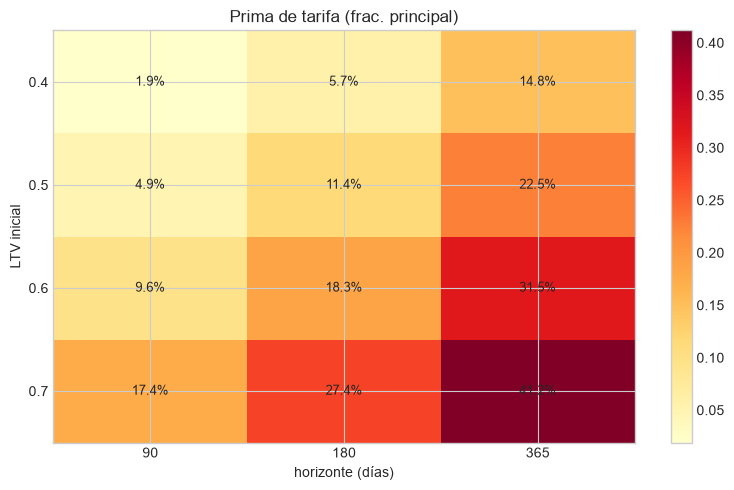

In [5]:
tab=compute_premium_table(mcmc, start_price, horizons_days=[90,180,365],
                          init_ltvs=[0.40,0.50,0.60,0.70], liq_ltv=0.80, friction=0.015,
                          principal_usd=PRINCIPAL, n_trajectories=N_SIMS, seed=SEED)
pv=tab.pivot(index='init_ltv',columns='horizon_days',values='tariff_premium_frac')
print('Prima de TARIFA (fracción del principal) por LTV inicial × horizonte:')
print(pv.to_string(float_format=lambda x:f'{x:.3f}'))
print('\nP(liquidación) por LTV × horizonte:')
print(tab.pivot(index='init_ltv',columns='horizon_days',values='p_liq').to_string(float_format=lambda x:f'{x:.3f}'))

fig,ax=plt.subplots(figsize=(8,5))
im=ax.imshow(pv.values,cmap='YlOrRd',aspect='auto')
ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns)
ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
ax.set_xlabel('horizonte (días)'); ax.set_ylabel('LTV inicial'); ax.set_title('Prima de tarifa (frac. principal)')
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax.text(j,i,f'{pv.values[i,j]:.1%}',ha='center',va='center',fontsize=9)
plt.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## 5. Cap. 7 — Buffer de volatilidad óptimo Bayesiano

Buffer $B^*(\alpha)$ = colateral extra (como % del inicial) para que una fracción $\alpha$ de las
trayectorias **no** se liquide. Al derivarse de la posterior, produce un rango, no un punto.
Comparamos SV Bayesiano vs Bootstrap i.i.d. (LTV inicial 0.50, 365 d).

Buffer requerido (% del colateral inicial) por nivel de supervivencia:
               SV_buffer_%  Bootstrap_buffer_%
supervivencia                                 
0.80                 0.608               0.794
0.90                 1.198               1.452
0.95                 1.974               2.166
0.99                 4.719               4.993


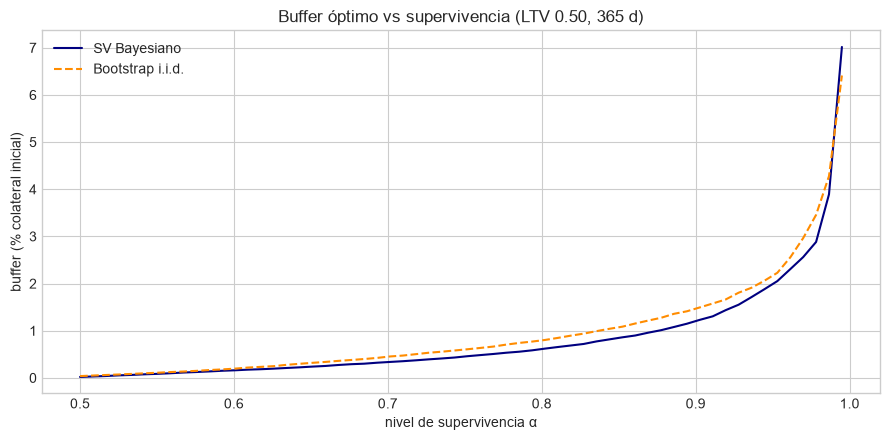

Trayectorias SV que NO requieren buffer: 48.3%


In [6]:
bias=BiasConfig(use_log_returns=True,drift_mode='zero')
bs_paths=MonteCarloPriceSimulator(price_tr,n_sims=N_SIMS,bias=bias).simulate_paths(365)
buf_sv=compute_bayesian_buffer_distribution(sv_paths,init_ltv=0.50,liq_ltv=0.80,principal_usd=PRINCIPAL)
buf_bs=compute_bayesian_buffer_distribution(bs_paths,init_ltv=0.50,liq_ltv=0.80,principal_usd=PRINCIPAL)

levels=[0.80,0.90,0.95,0.99]
rows=[{'supervivencia':a,
       'SV_buffer_%':find_bayesian_buffer(buf_sv,a)['buffer_pct@target'],
       'Bootstrap_buffer_%':find_bayesian_buffer(buf_bs,a)['buffer_pct@target']} for a in levels]
buftab=pd.DataFrame(rows).set_index('supervivencia')
print('Buffer requerido (% del colateral inicial) por nivel de supervivencia:')
print(buftab.to_string(float_format=lambda x:f'{x:.3f}'))

fig,ax=plt.subplots(figsize=(9,4.5))
grid=np.linspace(0.50,0.995,60)
ax.plot(grid,[find_bayesian_buffer(buf_sv,a)['buffer_pct@target'] for a in grid],color='navy',label='SV Bayesiano')
ax.plot(grid,[find_bayesian_buffer(buf_bs,a)['buffer_pct@target'] for a in grid],color='darkorange',ls='--',label='Bootstrap i.i.d.')
ax.set_xlabel('nivel de supervivencia α'); ax.set_ylabel('buffer (% colateral inicial)')
ax.set_title('Buffer óptimo vs supervivencia (LTV 0.50, 365 d)'); ax.legend()
plt.tight_layout(); plt.show()
frac0=(buf_sv['buffer_pct']==0).mean()
print(f'Trayectorias SV que NO requieren buffer: {frac0:.1%}')

## 6. Valor del enfoque Bayesiano: incertidumbre en la prima

El aporte central: la prima Bayesiana viene con un **intervalo de credibilidad** que un estimador
puntual (bootstrap) no entrega. Visualizamos la posterior de la prima de riesgo para la config de referencia.

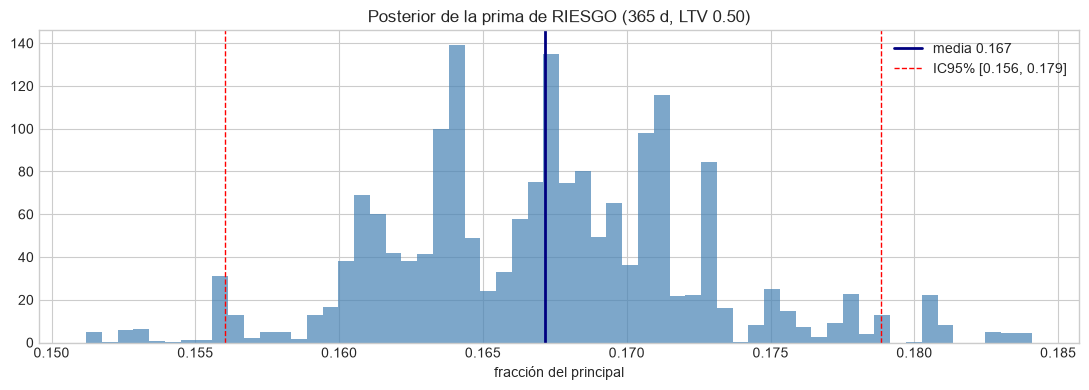

Prima de riesgo: media 0.1672, IC95% [0.1560, 0.1789] ($1560–$1789 sobre $10,000)


In [7]:
from tesis.bayesian.pricing.bayesian_premium import GammaSeverityMCMC
gm=GammaSeverityMCMC(lgl_liq)
gres=gm.run(n_iter=5000,burn_in=1000,seed=SEED,verbose=False)
elgl=gres['alpha']/gres['beta']
rp_samples=res['p_liq']*elgl

fig,ax=plt.subplots(figsize=(11,4))
ax.hist(rp_samples,bins=60,density=True,color='steelblue',alpha=0.7)
ax.axvline(rp_samples.mean(),color='navy',lw=2,label=f'media {rp_samples.mean():.3f}')
ci=np.percentile(rp_samples,[2.5,97.5])
ax.axvline(ci[0],color='red',ls='--',lw=1); ax.axvline(ci[1],color='red',ls='--',lw=1,label=f'IC95% [{ci[0]:.3f}, {ci[1]:.3f}]')
ax.set_title('Posterior de la prima de RIESGO (365 d, LTV 0.50)'); ax.set_xlabel('fracción del principal'); ax.legend()
plt.tight_layout(); plt.show()
print(f'Prima de riesgo: media {rp_samples.mean():.4f}, IC95% [{ci[0]:.4f}, {ci[1]:.4f}] (${ci[0]*PRINCIPAL:.0f}–${ci[1]*PRINCIPAL:.0f} sobre ${PRINCIPAL:,.0f})')

## 7. Conclusiones de la Fase 3

- **Cap. 5:** trayectorias SV que propagan incertidumbre epistémica + aleatórica; el SV es
  *condicional* (difiere del bootstrap en horizontes cortos) y converge a la vol incondicional a 1 año.
- **Cap. 6:** modelo frecuencia-severidad Bayesiano operativo — frecuencia de las trayectorias SV,
  severidad LGL con Gamma posterior (MCMC). La prima de riesgo integra ambas fuentes.
- **Cap. 7:** tabla de primas por plazo×LTV y **buffer óptimo con intervalo de credibilidad**.
  El aporte frente a la línea base frecuentista: cuantificar la **incertidumbre** de la prima/buffer.

**Pendiente (redacción):** Capítulos 5, 6 y 7. **Siguiente fase (4):** backtesting formal con split
temporal, extensión a ETH y métricas de evaluación (CRPS, coverage, log-score).